In [1]:
# Handwritten Character Recognition
# CodeAlpha Machine Learning Internship

# Import Libraries

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow Version:", tf.__version__)
print("Libraries Imported Successfully!")

TensorFlow Version: 2.21.0
Libraries Imported Successfully!


In [2]:
# Load MNIST Dataset

from tensorflow.keras.datasets import mnist

# Load training and testing data
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Display dataset shape
print("Training Data Shape:", x_train.shape)
print("Testing Data Shape:", x_test.shape)

print("Dataset Loaded Successfully!")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training Data Shape: (60000, 28, 28)
Testing Data Shape: (10000, 28, 28)
Dataset Loaded Successfully!


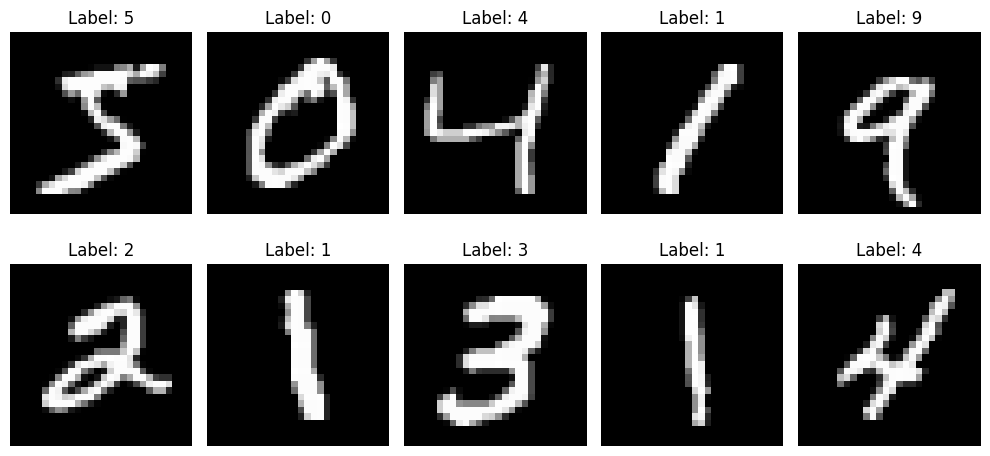

In [3]:
# Display Handwritten Digit Images

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [5]:
# Data Preprocessing

# Normalize the image data
x_train = x_train / 255.0
x_test = x_test / 255.0

print("Data Preprocessing Completed!")
print("Training Data Shape:", x_train.shape)
print("Testing Data Shape:", x_test.shape)

Data Preprocessing Completed!
Training Data Shape: (60000, 28, 28)
Testing Data Shape: (10000, 28, 28)


In [6]:
# Import CNN Libraries

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense

# Reshape image data
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

# Create CNN Model
model = Sequential([
    Conv2D(32, (3, 3), activation='relu',
           input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

# Display Model Summary
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 5408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       692,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 693,962 (2.65 MB)

 Trainable params: 693,962 (2.65 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# Compile the CNN Model

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train the Model

history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

print("Model Training Completed Successfully!")

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 31s 35ms/step - accuracy: 0.6706 - loss: 1.1257 - val_accuracy: 0.8915 - val_loss: 0.4041
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 29s 35ms/step - accuracy: 0.8830 - loss: 0.4004 - val_accuracy: 0.9163 - val_loss: 0.2795
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 41s 35ms/step - accuracy: 0.9021 - loss: 0.3277 - val_accuracy: 0.9313 - val_loss: 0.2375
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 29s 34ms/step - accuracy: 0.9142 - loss: 0.2898 - val_accuracy: 0.9348 - val_loss: 0.2174
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 29s 35ms/step - accuracy: 0.9230 - loss: 0.2569 - val_accuracy: 0.9427 - val_loss: 0.1961
Model Training Completed Successfully!


In [8]:
# Evaluate the Model

test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test
)

print("Test Accuracy:", test_accuracy * 100, "%")
print("Test Loss:", test_loss)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9302 - loss: 0.2324
Test Accuracy: 93.01999807357788 %
Test Loss: 0.2324061244726181


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step


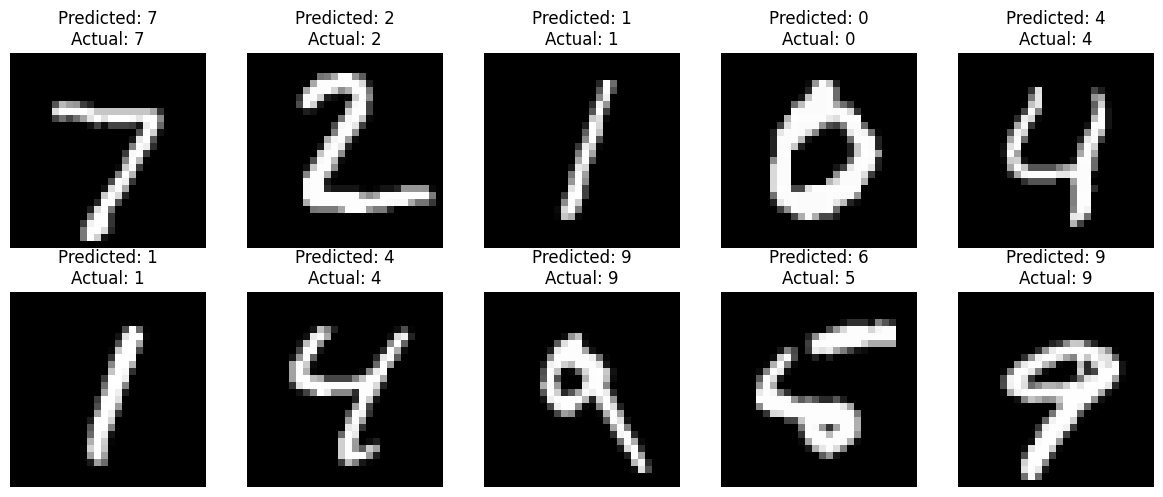

In [9]:
# Predict Handwritten Digits

predictions = model.predict(x_test[:10])

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')

    predicted_digit = np.argmax(predictions[i])

    plt.title(f"Predicted: {predicted_digit}\nActual: {y_test[i]}")

    plt.axis('off')

plt.tight_layout()
plt.show()

In [10]:
# Save the Trained Model

model.save("handwritten_digit_model.keras")

print("Model Saved Successfully!")

Model Saved Successfully!
